Device: cpu


config.json:   0%|          | 0.00/4.61k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  982MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B /  982MB            

...

special_tokens_map.json:   0%|          | 0.00/120 [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

Upload an image


Saving 133866935675791784.jpg to 133866935675791784.jpg


[transformers] We strongly recommend passing in an `attention_mask` since your input_ids may be padded. See https://huggingface.co/docs/transformers/troubleshooting#incorrect-output-when-padding-tokens-arent-masked.
You may ignore this warning if your `pad_token_id` (50256) is identical to the `bos_token_id` (50256), `eos_token_id` (50256), or the `sep_token_id` (None), and your input is not padded.


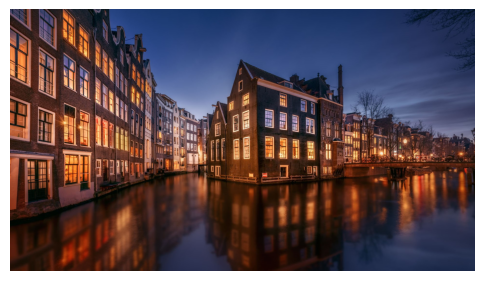

Image Caption: a large building with a clock on it 


In [1]:

!pip -q install transformers torch pillow

import torch
from PIL import Image
from transformers import VisionEncoderDecoderModel, ViTImageProcessor, AutoTokenizer
from google.colab import files
import matplotlib.pyplot as plt

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

model_name = "nlpconnect/vit-gpt2-image-captioning"

model = VisionEncoderDecoderModel.from_pretrained(model_name).to(device)
processor = ViTImageProcessor.from_pretrained(model_name)
tokenizer = AutoTokenizer.from_pretrained(model_name)

print("Upload an image")
uploaded = files.upload()

for filename in uploaded:
    image = Image.open(filename).convert("RGB")
    pixel_values = processor(images=image, return_tensors="pt").pixel_values.to(device)

    with torch.no_grad():
        output_ids = model.generate(
            pixel_values,
            max_length=30,
            num_beams=2
        )

    caption = tokenizer.decode(output_ids[0], skip_special_tokens=True)

    plt.figure(figsize=(6, 4))
    plt.imshow(image)
    plt.axis("off")
    plt.show()

    print("Image Caption:", caption)
